## Risk Alert Calssifier

**Import Libraries**

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression 

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, recall_score, precision_score, f1_score,roc_auc_score,roc_curve

from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from scipy.stats import randint

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN


**Load Dataset**

In [3]:
# Load the dataset 
df = pd.read_csv("Risk_Alert_Classifier_Dataset.csv")

# Display the first 5 rows 
print(df.head())

# Check missing values
print(df.isnull().sum())

# Check the data type 
print(df.dtypes)

   customer_id   age  gender   region employment_type  annual_income_inr  \
0       500001  43.0  Female      NaN        Salaried            82242.0   
1       500002  29.0  Female  Central        Salaried            32769.0   
2       500003  36.0    Male     East        Salaried            39731.0   
3       500004  28.0    Male    North      Unemployed            38990.0   
4       500005  36.0  Female     East   Self-Employed            41043.0   

   credit_score  credit_utilization_ratio  missed_payments_12m  \
0           NaN                     0.120                    1   
1         647.0                     0.337                    1   
2         727.0                     0.175                    0   
3         553.0                     0.472                    7   
4         732.0                     0.418                    1   

   avg_late_payment_days  monthly_transaction_count  monthly_spend_inr  \
0                    2.2                         39            33889.0  

**Interpretation:** Dataset CSV file se load kiya gaya hai. head() first five records dikhata hai, isnull().sum() har column mein missing values count karta hai, aur dtypes har column ka data type batata hai. Is step se dataset ki basic structure aur data quality samajhne mein madad milti hai.

## Part B: Dataset Understanding & Preparation

In [4]:
print("Risk Status Value Counts:")
print(df['risk_status'].value_counts())

print("\nRisk Status Percentage:")

print(
    (df['risk_status'].value_counts(normalize=True)*100).round(2)
)

Risk Status Value Counts:
risk_status
0    4043
1     557
Name: count, dtype: int64

Risk Status Percentage:
risk_status
0    87.89
1    12.11
Name: proportion, dtype: float64


**Interpretation:** Is code se har risk_status class ke records aur unki percentage pata chalti hai. Isse identify kar sakte hain ki dataset balanced hai ya imbalanced. Agar ek class ke records doosri class se bahut zyada hain, toh model majority class ki taraf biased ho sakta hai.

**7. Identify input features and target variable**

In [5]:
# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# Input features
X = df.drop(columns=['risk_status'])

# Target variable
y = df['risk_status']

print("Input Features:")
print(X.columns.tolist())

print("Target Variable:")
print(y.name)

Input Features:
['customer_id', 'age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr']
Target Variable:
risk_status


**Interpretation:** Column names se extra spaces remove kiye gaye hain. X mein model ke input features hain, jabki y mein target variable risk_status hai, jise model predict karega. Target column ko input features se remove karne se target leakage ka risk kam hota hai.

**8. Perform train-test split**

In [6]:
# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test =train_test_split(X,y, test_size = 0.2, random_state = 42)

print("Training set size:", x_train.shape)
print("Testing set size:", x_test.shape)

print("\nTraining set class distribution:")
print(y_train.value_counts(normalize = True).round(3))

print("\nTesting set class distribution:")
print(y_test.value_counts(normalize = True).round(3))


Training set size: (3680, 18)
Testing set size: (920, 18)

Training set class distribution:
risk_status
0    0.882
1    0.118
Name: proportion, dtype: float64

Testing set class distribution:
risk_status
0    0.865
1    0.135
Name: proportion, dtype: float64


**Interpretation:** Dataset ko 80% training data aur 20% testing data mein divide kiya gaya hai. Training data model ko train karne ke liye aur testing data unseen records par performance evaluate karne ke liye use hota hai. random_state=42 same split ko repeat karne mein help karta hai.

**9. Identify missing values and apply KNN Imputer for multivariate imputation.**

In [7]:
# Create a KNN imputer object
imputer = KNNImputer(n_neighbors=5)

# Apply the imputer to numerical features
x_train_imputer = imputer.fit_transform(x_train.select_dtypes([np.number]))

# Apply the imputer to test data
x_test_imputer = imputer.transform(x_test.select_dtypes([np.number]))

numeric_columns = x_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = x_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Columns:", numeric_columns)
print("Categorical Columns:", categorical_columns)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5)),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Fit on training data and transform training/testing data
X_train_processed = preprocessor.fit_transform(x_train)
X_test_processed = preprocessor.transform(x_test)

print("Training Data After Preprocessing:", X_train_processed.shape)
print("Testing Data After Preprocessing:", X_test_processed.shape)



Numerical Columns: ['customer_id', 'age', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr']
Categorical Columns: ['gender', 'region', 'employment_type', 'last_transaction_date']
Training Data After Preprocessing: (3680, 117)
Testing Data After Preprocessing: (920, 117)


**Interpretation:**
- KNNImputer: Numerical columns ki missing values ko nearby records ke basis par estimate karta hai.
- StandardScaler: Numerical features ko comparable scale par laata hai.
- SimpleImputer: Categorical columns ki missing values ko most frequent category se fill karta hai.
- OneHotEncoder: Categorical values ko numerical representation mein convert karta hai.
- ColumnTransformer: Numerical aur categorical pipelines ko combine karta hai.
- fit_transform(x_train): Training data se preprocessing rules learn karke training data transform karta hai.
- transform(x_test): Wahi learned rules testing data par apply karta hai, bina test data par dobara fit kiye.

## Part C: Baseline Classification Model

**10. Implement Logistic Regression as a baseline model**

In [8]:
number_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("Scale_values", StandardScaler())
])

In [9]:
text_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("convert_to_string", OneHotEncoder(handle_unknown="ignore"))
])

In [10]:
prepare_data = ColumnTransformer([
    ("numbers", number_steps, numeric_columns),
    ("text", text_steps, categorical_columns)
])

In [11]:
model = Pipeline([
    ("data_preparation", prepare_data),
    ("prediction", LogisticRegression(max_iter=2000))
])

model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('data_preparation', ...), ('prediction', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['customer_id','age','gender',...,'account_tenure_months', 'last_transaction_date','debt_balance_inr']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numbers', ...), ('text', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

In [12]:

# Use the same preprocessing pipeline
preprocessor = clone(preprocessor)

X_train_processed = preprocessor.fit_transform(x_train)
X_test_processed = preprocessor.transform(x_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

# Train a fresh model
model = LogisticRegression(max_iter=5000)
model.fit(X_train_processed, y_train)

# Generate predictions
y_pred = model.predict(X_test_processed)

print("Actual values:", len(y_test))
print("Predicted values:", len(y_pred))
print("Predictions:", y_pred[:10])

Training shape: (3680, 117)
Testing shape: (920, 117)
Actual values: 920
Predicted values: 920
Predictions: [0 0 0 0 0 0 0 0 0 0]


**Interpretation**
- Numerical pipeline: Missing numerical values ko median se fill karti hai aur StandardScaler se scale karti hai.
- Categorical pipeline: Missing categorical values ko most frequent category se fill karti hai aur OneHotEncoder se numerical format mein convert karti hai.
- ColumnTransformer: Dono pipelines ko unke respective columns par apply karta hai.
- Logistic Regression: Processed features ka use karke risk_status ki prediction karta hai.
- model.fit(x_train, y_train): Training data se model ko patterns sikhata hai.

**Q11. Generate and interpret evaluation metrics**

**A. Confusion Matrix**

Confusion Matrix:
[[795   1]
 [  1 123]]


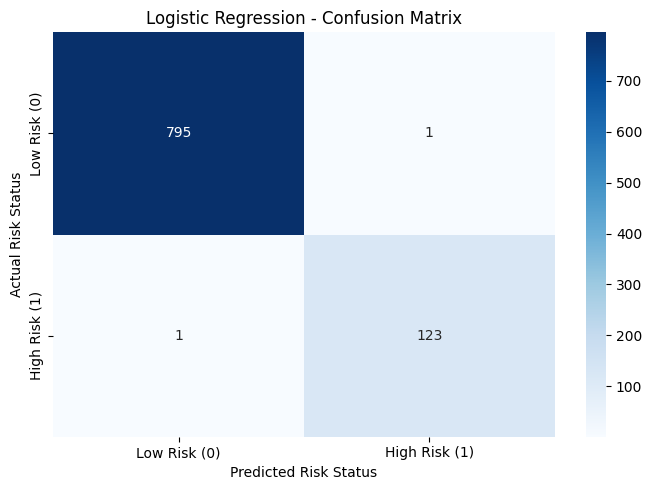

In [13]:
y_pred = model.predict(X_test_processed)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk (0)", "High Risk (1)"],
    yticklabels=["Low Risk (0)", "High Risk (1)"]
)

plt.xlabel("Predicted Risk Status")
plt.ylabel("Actual Risk Status")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

**Interpretation:**
Confusion Matrix actual risk status ane model na predicted risk status vachche comparison kare chhe.
- TN: Actual Low Risk, predicted Low Risk.
- FP: Actual Low Risk, predicted High Risk.
- FN: Actual High Risk, predicted Low Risk.
- TP: Actual High Risk, predicted High Risk.

**C. Precision, Recall and F1-Score**

In [ ]:
# precision
precision = precision_score(
    y_test, y_pred, zero_division=0)

# recall

recall = recall_score(
    y_test, y_pred, zero_division=0
)

# F1

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("Precision:", precision,4)
print("Recall:", recall,4)
print("F1 Score:", f1,4)



Precision: 0.9919354838709677 4
Recall: 0.9919354838709677 4
F1 Score: 0.9919354838709677 4


**Interpretation:**
- Precision: Model e jetla customers ne High Risk predict karya, ema actual High Risk ketla hata.
- Recall: Total actual High Risk customers mathi model e ketla ne identify karya.
- F1-Score: Precision ane recall vachche harmonic mean chhe.

Credit Risk interpretation: High Risk recall important chhe, karan ke actual High Risk customer ne Low Risk predict karvo False Negative chhe.

**Q12. Type-I and Type-II Errors**

In [ ]:
y_pred = model.predict(X_test_processed)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print("\nTrue Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

# Type-I and Type-II errors
print("\nType-I Error (FP):", fp)
print("Type-II Error (FN):", fn)

Confusion Matrix:
[[795   1]
 [  1 123]]

True Negative (TN): 795
False Positive (FP): 1
False Negative (FN): 1
True Positive (TP): 123

Type-I Error (FP): 1
Type-II Error (FN): 1


**Interpretation:**
- Type-I Error (False Positive): Actual Low Risk customer ne model High Risk predict kare chhe.
- Type-II Error (False Negative): Actual High Risk customer ne model Low Risk predict kare chhe.

## Part D — Handling Imbalanced Data

**Q13. Demonstrate the impact of class imbalance**

Class Counts:
risk_status
0    3247
1     433
Name: count, dtype: int64

Class percentage:
risk_status
0    88.23
1    11.77
Name: count, dtype: float64


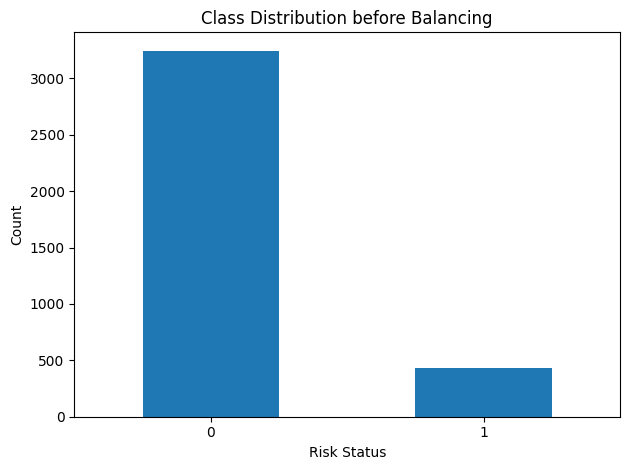

In [ ]:
class_counts = pd.Series(y_train).value_counts().sort_index()

print("Class Counts:")
print(class_counts)

print("\nClass percentage:")
print((class_counts/ len(y_train)*100).round(2))

class_counts.plot(kind="bar")
plt.title("Class Distribution before Balancing")
plt.xlabel("Risk Status")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:**
- value_counts() har class ke records count karta hai.
- Percentage batata hai ki training data ka kitna hissa har class mein hai.
- Bar graph se pata chalta hai ki classes balanced hain ya imbalanced.
- Agar risk_status = 1 high-risk ko represent karta hai aur uske records kam hain, toh model high-risk cases ko miss kar sakta hai.

**Q14. Apply Under-Sampling, Over-Sampling, SMOTE and ADASYN**

In [ ]:
results = []

def evaluate_model(name, model, X_test_data, y_test_data):
    predictions = model.predict(X_test_data)
    probabilities = model.predict_proba(X_test_data)[:, 1]

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test_data, predictions),
        "Precision": precision_score(
            y_test_data, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_data, predictions, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_data, predictions, pos_label=1, zero_division=0
        ),
        "AUC-ROC": roc_auc_score(y_test_data, probabilities)
    }

    results.append(result)
    return result


# Baseline: no balancing
baseline_model = LogisticRegression(max_iter=5000)
baseline_model.fit(X_train_processed, y_train)

evaluate_model(
    "Baseline Logistic Regression",
    baseline_model,
    X_test_processed,
    y_test
)

print("Baseline model trained.")

Baseline model trained.


In [ ]:
# Apply four balancing techniques

samplers = {
    "Under-Sampling": RandomUnderSampler(random_state=42),
    "Over-Sampling": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42)
}

balanced_models = {}

for name, sampler in samplers.items():

    try:
        # Balance training data only
        X_resampled, y_resampled = sampler.fit_resample(
            X_train_processed, y_train
        )

        # Train a new model
        model = LogisticRegression(max_iter=5000)
        model.fit(X_resampled, y_resampled)

        balanced_models[name] = model

        evaluate_model(
            name,
            model,
            X_test_processed,
            y_test
        )

        print(
            name,
            "| Before:", pd.Series(y_train).value_counts().to_dict(),
            "| After:", pd.Series(y_resampled).value_counts().to_dict()
        )

    except Exception as error:
        print(name, "could not run:", error)

Under-Sampling | Before: {0: 3247, 1: 433} | After: {0: 433, 1: 433}
Over-Sampling | Before: {0: 3247, 1: 433} | After: {0: 3247, 1: 3247}
SMOTE | Before: {0: 3247, 1: 433} | After: {0: 3247, 1: 3247}
ADASYN | Before: {0: 3247, 1: 433} | After: {0: 3247, 1: 3238}


**Interpretation:**
- fit_resample() training data ko balance karta hai.
- model.fit() balanced data se Logistic Regression train karta hai.
- X_test_processed aur y_test original test data hain; inhe balance nahi karna chahiye.
- balanced_models har successfully trained model ko save karta hai.
- try-except kisi technique mein error aane par notebook ko aage chalne deta hai.

**15. Compare performance before and after balancing**

                       Model  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Baseline Logistic Regression    0.9978     0.9919  0.9919    0.9919   1.0000
              Under-Sampling    0.9902     0.9323  1.0000    0.9650   1.0000
               Over-Sampling    0.9935     0.9538  1.0000    0.9764   1.0000
                       SMOTE    0.9978     0.9841  1.0000    0.9920   1.0000
                      ADASYN    0.9924     0.9466  1.0000    0.9725   0.9999


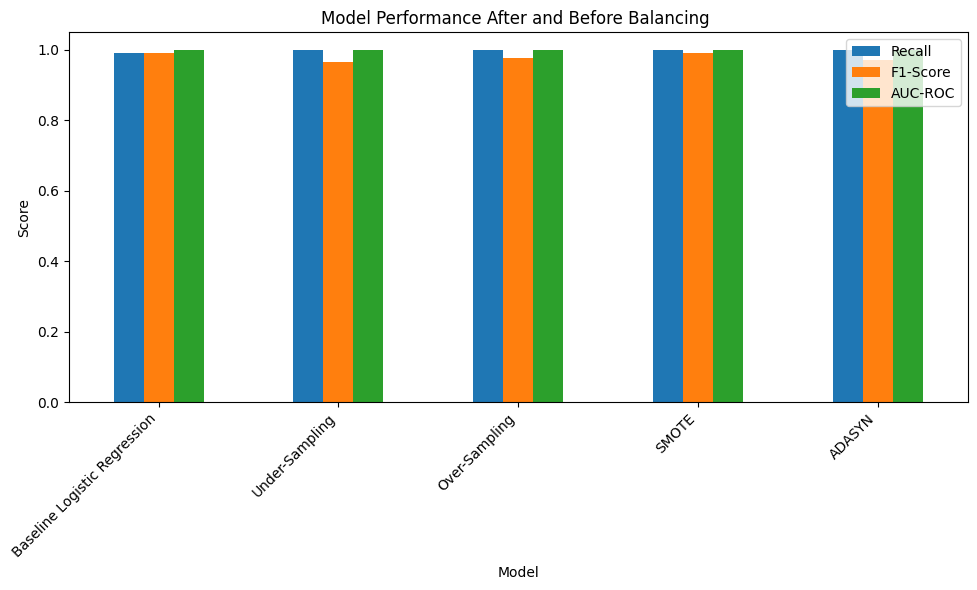

In [ ]:
comparison_df = pd.DataFrame(results)

print(
    comparison_df.round(4).to_string(index=False)
)

comparison_df.plot(
    x="Model",
    y=["Recall","F1-Score","AUC-ROC"],
    kind="bar",
    figsize=(10,6)
)

plt.title("Model Performance After and Before Balancing ")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Interpretation:**
- Recall: Actual high-risk cases mein se kitne model ne identify kiye.
- F1-Score: Precision aur recall ke beech balance measure karta hai.
- AUC-ROC: Model high-risk aur low-risk cases ko kitna achha distinguish karta hai.
- Bar graph se baseline ko balancing techniques ke saath compare kar sakte ho.

# Part E — Tree-Based Classification Models

**16. Implement Decision Tree Classifier**

In [ ]:
decision_tree = DecisionTreeClassifier(random_state=42)

decision_tree.fit(X_train_processed, y_train)

dt_predictions = decision_tree.predict(X_test_processed)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_predictions))

print("\nClassification Report:", classification_report(y_test, dt_predictions, zero_division=0))

Decision Tree Accuracy: 0.9608695652173913

Classification Report:               precision    recall  f1-score   support

           0       0.98      0.97      0.98       796
           1       0.83      0.90      0.86       124

    accuracy                           0.96       920
   macro avg       0.91      0.93      0.92       920
weighted avg       0.96      0.96      0.96       920



**Interpretation:**
- DecisionTreeClassifier() classification model banata hai.
- fit() training data se patterns learn karta hai.
- predict() test data ke risk labels predict karta hai.
- Accuracy total correct predictions ka proportion hai.
- Classification Report precision, recall, F1-score aur support dikhata hai.

**17. Analyze overfitting using training and testing performance**

In [ ]:
dt_train_predictions = decision_tree.predict(X_train_processed)
dt_test_predictions = decision_tree.predict(X_test_processed)

dt_train_accuracy = accuracy_score(y_train, dt_train_predictions)
dt_test_accuracy = accuracy_score(y_test, dt_test_predictions)

print("Training Accuracy:", round(dt_train_accuracy, 4))
print("Testing Accuracy:", round(dt_test_accuracy, 4))

if dt_test_accuracy - dt_train_accuracy > 0.1:
    print("Possible overfitting: training accuracy is much higher.")
else:
    print("No large accuracy gap detected; check other metrics too.")

Training Accuracy: 1.0
Testing Accuracy: 0.9609
No large accuracy gap detected; check other metrics too.


**Interpretation:**
- Training accuracy batati hai ki model training data par kitna sahi hai.
- Testing accuracy batati hai ki model unseen data par kitna sahi hai.
- Agar training accuracy test accuracy se kaafi zyada hai, toh overfitting ka signal ho sakta hai.
- Code mein 0.1 ka matlab 10 percentage points ka gap hai; yeh ek simple rule of thumb hai, universal threshold nahi.

**18. Implement Random Forest Classifier**

In [ ]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

rf_predictions = random_forest.predict(X_test_processed)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

Random Forest Accuracy: 0.9847826086956522

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       796
           1       0.99      0.90      0.94       124

    accuracy                           0.98       920
   macro avg       0.99      0.95      0.97       920
weighted avg       0.98      0.98      0.98       920



**Interpretation:**
- n_estimators=100 ka matlab hai 100 decision trees use karna.
- random_state=42 results ko reproducible banane mein help karta hai.
- n_jobs=-1 available CPU cores use karne deta hai.
- Classification report se pata chalta hai ki model high-risk customers ko kitna achha identify karta hai.

**19. Compare Decision Tree vs Random Forest**

        Model  Train Accuracy  Test Accuracy  Recall  F1-Score  AUC-ROC
Decision Tree             1.0         0.9609  0.8952    0.8605   0.9331
Random Forest             1.0         0.9848  0.8952    0.9407   0.9997


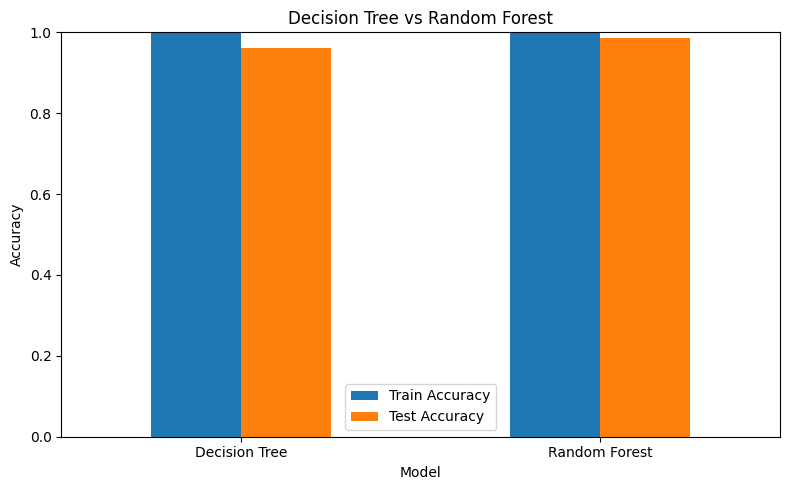

In [ ]:
tree_comparison = []

for name, model in [
    ("Decision Tree", decision_tree),
    ("Random Forest", random_forest)
]:
    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    tree_comparison.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train, model.predict(X_train_processed)
        ),
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "AUC-ROC": roc_auc_score(y_test, probabilities)
    })

tree_comparison_df = pd.DataFrame(tree_comparison)

print(tree_comparison_df.round(4).to_string(index=False))

tree_comparison_df.set_index("Model")[
    ["Train Accuracy", "Test Accuracy"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:**
- Train Accuracy: Training data par model ki performance.
- Test Accuracy: Unseen test data par performance.
- Recall: Actual high-risk customers mein se kitnon ko identify kiya.
- F1-Score: Precision aur Recall ke beech balance.
- AUC-ROC: Model high-risk aur low-risk customers ko kitna achha distinguish karta hai.

# Part F — Hyperparameter Tuning

**20. Apply RandomizedSearchCV**

In [ ]:
# Decision Tree: Randomized Search

dt_parameters = {
    "max_depth": [3, 5, 8, 10, 15, None],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 10),
    "criterion": ["gini", "entropy"]
}

dt_random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=dt_parameters,
    n_iter=15,
    scoring="recall",
    cv=3,
    random_state=42,
    n_jobs=-1
)

dt_random_search.fit(X_train_processed, y_train)

best_dt = dt_random_search.best_estimator_

print("Best Decision Tree Parameters:")
print(dt_random_search.best_params_)

print("Best CV Recall:", round(dt_random_search.best_score_, 4))

Best Decision Tree Parameters:
{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 7}
Best CV Recall: 0.8823


**Interpretation:**
- max_depth: Tree ki maximum depth control karta hai.
- min_samples_split: Node ko split karne ke liye minimum samples.
- min_samples_leaf: Har leaf mein minimum samples.
- criterion: Split quality measure karne ka method.
- n_iter=15: 15 parameter combinations try honge.
- cv=3: Training data ko 3 folds mein evaluate kiya jayega.
- scoring="recall": Search high-risk class (1) ka Recall optimize karega.

**21. Apply GridSearchCV for fine-tuning**

In [ ]:
# Fine-tune the best Decision Tree

dt_grid_parameters = {
    "max_depth": [5, 8, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt_grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_grid_parameters,
    scoring="recall",
    cv=3,
    n_jobs=-1
)

dt_grid_search.fit(X_train_processed, y_train)

best_dt_grid = dt_grid_search.best_estimator_

print("Best Grid Search Decision Tree Parameters:")
print(dt_grid_search.best_params_)

print("Best CV Recall:", round(dt_grid_search.best_score_, 4))

Best Grid Search Decision Tree Parameters:
{'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV Recall: 0.8708


**Interpretation:**
- Grid mein 5 × 3 × 3 = 45 parameter combinations hain.
- cv=3 ke saath har combination ko 3 validation folds par evaluate kiya jata hai.
- best_params_ best parameter combination deta hai.
- best_score_ best cross-validation Recall deta hai.

In [ ]:
# Fine-tune the best Random Forest

rf_grid_parameters = {
    "n_estimators": [100, 150],
    "max_depth": [10, 15, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}

rf_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=rf_grid_parameters,
    scoring="recall",
    cv=3,
    n_jobs=-1
)

rf_grid_search.fit(X_train_processed, y_train)

best_rf_grid = rf_grid_search.best_estimator_

print("Best Grid Search Random Forest Parameters:")
print(rf_grid_search.best_params_)

print("Best CV Recall:", round(rf_grid_search.best_score_, 4))

Best Grid Search Random Forest Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Recall: 0.9307


**Interpretation:**
- n_estimators forest mein trees ki count set karta hai.
- max_depth har tree ki depth limit karta hai.
- min_samples_split aur min_samples_leaf tree ki complexity control karte hain.
- max_features="sqrt" har split par features ka square-root-sized subset consider karta hai.
- Is grid mein 2 × 3 × 2 × 2 × 1 = 24 combinations hain; 3-fold CV ke saath 72 model fits honge.

**22. Compare tuned vs untuned models**

                 Model  Accuracy  Recall  F1-Score  AUC-ROC
Decision Tree - Before    0.9609  0.8952    0.8605   0.9331
 Decision Tree - Tuned    0.9587  0.8468    0.8468   0.8888
Random Forest - Before    0.9848  0.8952    0.9407   0.9997
 Random Forest - Tuned    0.9859  0.9032    0.9451   0.9998


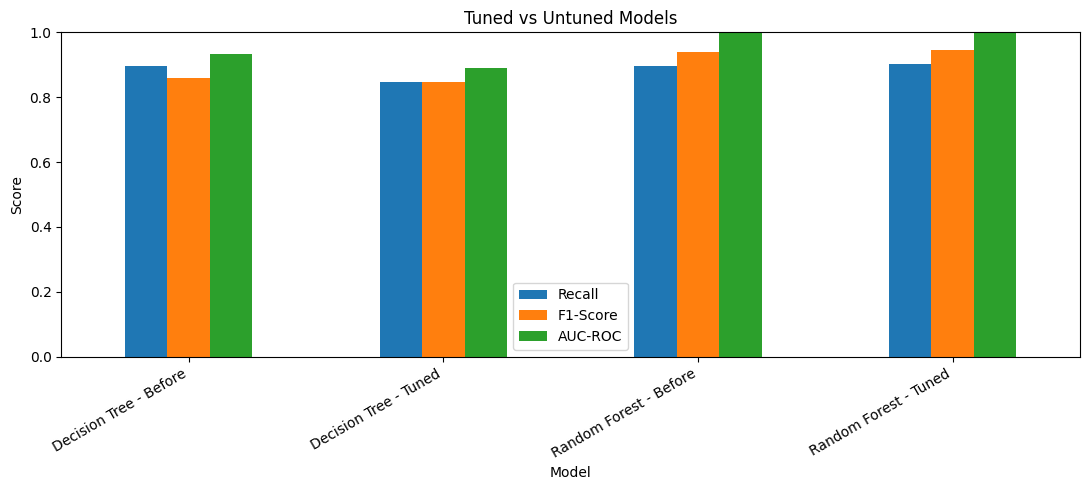

In [ ]:
tuning_models = {
    "Decision Tree - Before": decision_tree,
    "Decision Tree - Tuned": best_dt_grid,
    "Random Forest - Before": random_forest,
    "Random Forest - Tuned": best_rf_grid
}

tuning_results = []

for name, model in tuning_models.items():
    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    tuning_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "AUC-ROC": roc_auc_score(y_test, probabilities)
    })

tuning_df = pd.DataFrame(tuning_results)

print(tuning_df.round(4).to_string(index=False))

tuning_df.set_index("Model")[
    ["Recall", "F1-Score", "AUC-ROC"]
].plot(kind="bar", figsize=(11, 5))

plt.title("Tuned vs Untuned Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Interpretation**
- Accuracy: Overall correct predictions ka proportion.
- Recall: Actual high-risk customers mein se kitne identify hue.
- F1-Score: Precision aur Recall ka balanced measure.
- AUC-ROC: Model ki classes ko distinguish karne ki ability.

# Part G — Model Evaluation & ROC Analysis

**23. Plot and interpret the ROC curve for all models**

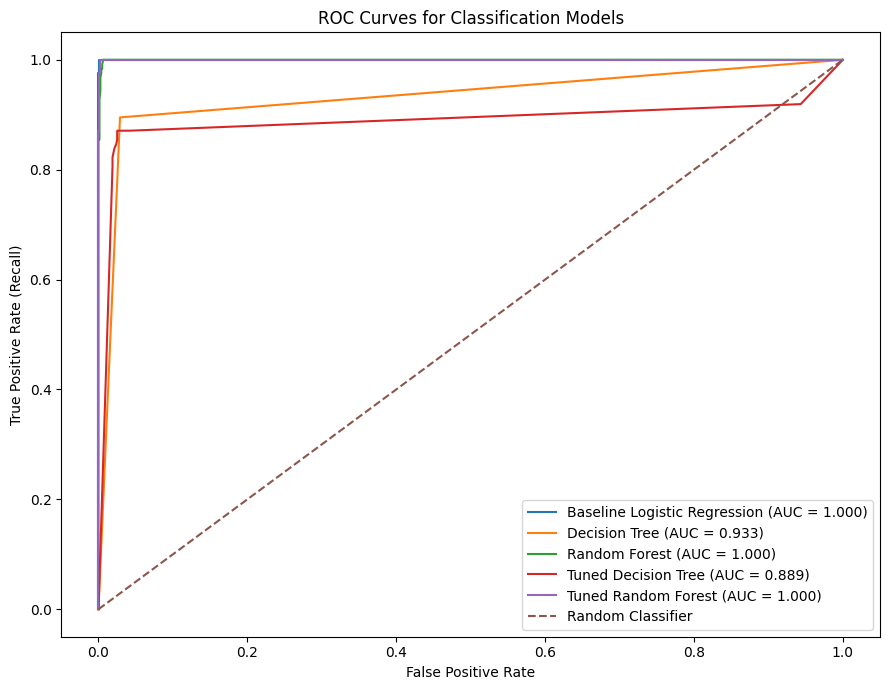

In [ ]:
roc_models = {
    "Baseline Logistic Regression": baseline_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Tuned Decision Tree": best_dt_grid,
    "Tuned Random Forest": best_rf_grid
}

plt.figure(figsize=(9, 7))

for name, model in roc_models.items():
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

# Random classification reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves for Classification Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation —**
- ROC Curve: Different probability thresholds par model kitne positive cases correctly identify karta hai aur kitne negative cases ko galti se positive batata hai, ye show karti hai.
- True Positive Rate (TPR): Actual high-risk customers mein se kitne ko model ne sahi identify kiya.
- False Positive Rate (FPR): Actual low-risk customers mein se kitne ko model ne galti se high-risk classify kiya.
- AUC: ROC curve ke neeche ka area. AUC jitna 1 ke close hoga, model ki ranking ability generally utni better hogi.
- Dashed diagonal line: Random classifier ka reference hai, jiska AUC approximately 0.5 hota hai.

**24. Compute and compare AUC-ROC scores**

                       Model  AUC-ROC
Baseline Logistic Regression   1.0000
         Tuned Random Forest   0.9998
               Random Forest   0.9997
               Decision Tree   0.9331
         Tuned Decision Tree   0.8888


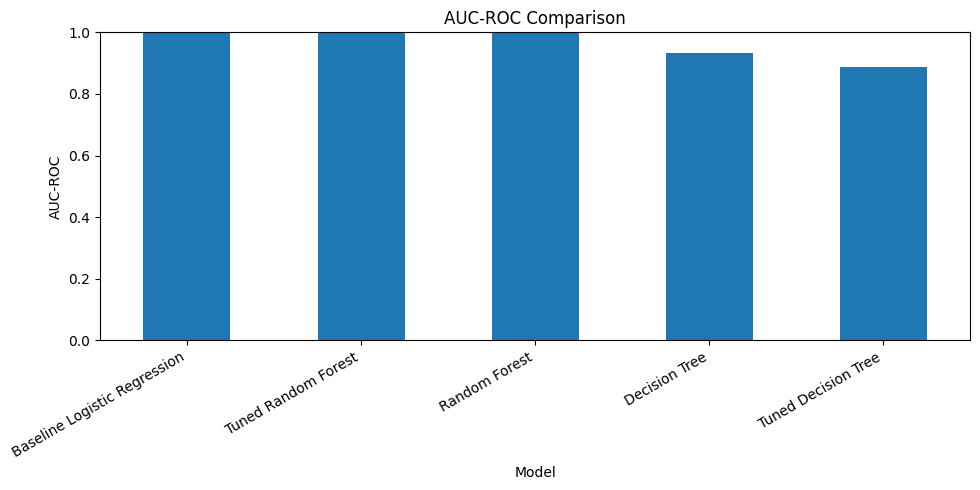

In [ ]:
auc_results = []

for name, model in roc_models.items():
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    auc_results.append({
        "Model": name,
        "AUC-ROC": roc_auc_score(y_test, probabilities)
    })

auc_df = pd.DataFrame(auc_results)
auc_df = auc_df.sort_values("AUC-ROC", ascending=False)

print(auc_df.round(4).to_string(index=False))

auc_df.plot(
    x="Model",
    y="AUC-ROC",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("AUC-ROC Comparison")
plt.ylabel("AUC-ROC")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Interpretation**
1. Har model ki high-risk probability calculate karte hain.
2. Us probability se AUC-ROC score nikalte hain.
3. Models ko highest AUC se lowest AUC ke order mein sort karte hain.
4. Bar graph ke through unki performance compare karte hain.

**25. Select the best final model — minimize false negatives**

In [ ]:
# Compare all candidate models for the final decision

final_candidates = {
    "Baseline Logistic Regression": baseline_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Tuned Decision Tree": best_dt_grid,
    "Tuned Random Forest": best_rf_grid
}

final_results = []

for name, model in final_candidates.items():
    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    final_results.append({
        "Model": name,
        "Recall High Risk": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "AUC-ROC": roc_auc_score(y_test, probabilities),
        "False Negatives": fn,
        "False Positives": fp,
        "Accuracy": accuracy_score(y_test, predictions)
    })

final_df = pd.DataFrame(final_results)

# First prioritize fewer false negatives, then higher recall and AUC
final_df = final_df.sort_values(
    by=["False Negatives", "Recall High Risk", "AUC-ROC"],
    ascending=[True, False, False]
)

print(final_df.round(4).to_string(index=False))

best_model_name = final_df.iloc[0]["Model"]
print("\nSelected model based on this ranking:", best_model_name)

best_final_model = final_candidates[best_model_name]

best_predictions = best_final_model.predict(X_test_processed)

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test, best_predictions, labels=[0, 1]))

print("\nFinal Classification Report:")
print(classification_report(y_test, best_predictions, zero_division=0))

                       Model  Recall High Risk  F1-Score  AUC-ROC  False Negatives  False Positives  Accuracy
Baseline Logistic Regression            0.9919    0.9919   1.0000                1                1    0.9978
         Tuned Random Forest            0.9032    0.9451   0.9998               12                1    0.9859
               Random Forest            0.8952    0.9407   0.9997               13                1    0.9848
               Decision Tree            0.8952    0.8605   0.9331               13               23    0.9609
         Tuned Decision Tree            0.8468    0.8468   0.8888               19               19    0.9587

Selected model based on this ranking: Baseline Logistic Regression

Final Confusion Matrix:
[[795   1]
 [  1 123]]

Final Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       796
           1       0.99      0.99      0.99       124

    accuracy                  

**Interpretation —**
Code sabse pehle lowest false negatives wale model ko priority deta hai. Agar do models ke false negatives equal hon, toh higher recall aur phir higher AUC ko priority milti hai.

# Final Conclusion — Credit Risk Classification

In this project, I developed a Credit Risk Classification system to identify high-risk customers using machine learning techniques. The dataset was analyzed and preprocessed by handling missing values, scaling numerical features, and encoding categorical features.

Different classification models were evaluated, including Logistic Regression, Decision Tree, and Random Forest. Hyperparameter tuning was performed using RandomizedSearchCV and GridSearchCV to improve model performance. I also compared model performance using Accuracy, Precision, Recall, F1-Score, and AUC-ROC.

Because the dataset contains an imbalance between low-risk and high-risk customers, accuracy alone is not sufficient to evaluate the models. Special attention was given to high-risk recall and false negatives, as missing a high-risk customer can lead to potential financial losses.

Finally, the models were compared using ROC curves, AUC-ROC scores, and confusion matrices to identify a suitable final model. The best model should be selected based on its ability to identify high-risk customers while maintaining an acceptable balance between false positives and false negatives.

This project improved my understanding of data preprocessing, class imbalance, model training, hyperparameter tuning, and classification model evaluation. The developed approach can support credit risk assessment, although further validation is required before using it in a real-world financial environment.